In [ ]:
!pip install --quiet --upgrade kaggle scikit-learn
import os, torch, numpy as np, pandas as pd
os.environ["KAGGLE_API_TOKEN"] = "PASTE_YOUR_TOKEN"
!mkdir --parents ~/.kaggle && echo "$KAGGLE_API_TOKEN" > ~/.kaggle/access_token && chmod 600 ~/.kaggle/access_token
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cuda


In [ ]:
!kaggle competitions download --competition cassava-leaf-disease-classification --path /content/data
!unzip -q -o /content/data/cassava-leaf-disease-classification.zip "train_images/*" -d /content/data
!wget --quiet --output-document /content/split_v1_seed42.csv https://raw.githubusercontent.com/Justine-abc/cassavacheck/main/data/split_v1_seed42.csv
!wget --quiet --output-document /content/mobilenetv3_baseline.pt https://raw.githubusercontent.com/Justine-abc/cassavacheck/main/models/mobilenetv3_baseline.pt
labels = pd.read_csv("/content/split_v1_seed42.csv")
image_directory = "/content/data/train_images"
validation_frame = labels[labels.split == "validation"].reset_index(drop=True)
print(len(validation_frame), "validation images;", os.path.getsize("/content/mobilenetv3_baseline.pt") // 1_000_000, "MB of weights")

100% 5.76G/5.76G [01:07<00:00, 91.4MB/s]

3210 validation images; 17 MB of weights


In [ ]:
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image
import torch.nn as nn

class CassavaDataset(Dataset):
    def __init__(self, frame, transform): self.frame, self.transform = frame.reset_index(drop=True), transform
    def __len__(self): return len(self.frame)
    def __getitem__(self, index):
        row = self.frame.iloc[index]
        return self.transform(Image.open(f"{image_directory}/{row.image_id}").convert("RGB")), int(row.label)

eval_transform = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224), transforms.ToTensor(),
                                     transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
model = models.mobilenet_v3_large(weights=None)
model.classifier[3] = nn.Linear(model.classifier[3].in_features, 5)
model.load_state_dict(torch.load("/content/mobilenetv3_baseline.pt", map_location=device)); model = model.to(device).eval()

def collect_logits(frame):
    loader = DataLoader(CassavaDataset(frame, eval_transform), batch_size=128, num_workers=2)
    logits, targets = [], []
    with torch.no_grad():
        for images, batch_targets in loader:
            logits.append(model(images.to(device)).cpu()); targets.append(batch_targets)
    return torch.cat(logits), torch.cat(targets)

validation_logits, validation_targets = collect_logits(validation_frame)
print("logits:", tuple(validation_logits.shape))

logits: (3210, 5)


In [ ]:
from sklearn.model_selection import train_test_split
fit_index, measure_index = train_test_split(np.arange(len(validation_frame)), test_size=0.5, stratify=validation_frame["label"], random_state=42)
fit_logits, fit_targets = validation_logits[fit_index], validation_targets[fit_index]
measure_logits, measure_targets = validation_logits[measure_index], validation_targets[measure_index]

# Temperature scaling: one number that divides the logits; found by minimising negative log-likelihood on the fit half
log_temperature = torch.zeros(1, requires_grad=True)
optimizer = torch.optim.LBFGS([log_temperature], lr=0.1, max_iter=200)
def closure():
    optimizer.zero_grad()
    loss = nn.functional.cross_entropy(fit_logits / log_temperature.exp(), fit_targets)
    loss.backward(); return loss
optimizer.step(closure)
temperature = float(log_temperature.exp())
print(f"fitted temperature: {temperature:.3f}  (1.0 would mean the model was already calibrated; above 1.0 means it was over-confident)")

fitted temperature: 0.931  (1.0 would mean the model was already calibrated; above 1.0 means it was over-confident)


uncalibrated  ECE 0.0275 | NLL 0.5066 | accuracy 0.8249 | mean confidence 0.8024
calibrated    ECE 0.0296 | NLL 0.5040 | accuracy 0.8249 | mean confidence 0.8181


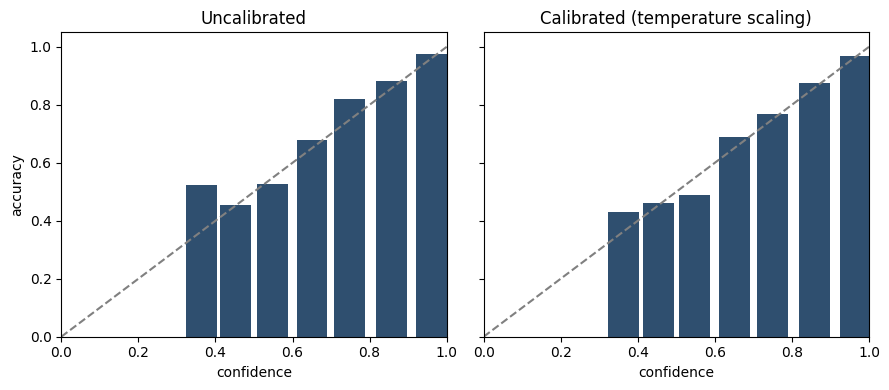

In [ ]:
import matplotlib.pyplot as plt
def expected_calibration_error(probabilities, targets, bins=15):
    confidence, prediction = probabilities.max(1)
    correct = (prediction == targets).float()
    edges = torch.linspace(0, 1, bins + 1); error = 0.0
    for low, high in zip(edges[:-1], edges[1:]):
        in_bin = (confidence > low) & (confidence <= high)
        if in_bin.any(): error += in_bin.float().mean() * (correct[in_bin].mean() - confidence[in_bin].mean()).abs()
    return float(error)

before = torch.softmax(measure_logits, 1)
after = torch.softmax(measure_logits / temperature, 1)
for name, probabilities in (("uncalibrated", before), ("calibrated", after)):
    nll = float(nn.functional.nll_loss(probabilities.clamp_min(1e-9).log(), measure_targets))
    accuracy = float((probabilities.argmax(1) == measure_targets).float().mean())
    print(f"{name:13s} ECE {expected_calibration_error(probabilities, measure_targets):.4f} | NLL {nll:.4f} | accuracy {accuracy:.4f} | mean confidence {float(probabilities.max(1).values.mean()):.4f}")

# Reliability diagram: confidence on x, actual accuracy on y; the diagonal is perfect calibration
fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharey=True)
for axis, (name, probabilities) in zip(axes, (("Uncalibrated", before), ("Calibrated (temperature scaling)", after))):
    confidence, prediction = probabilities.max(1); correct = (prediction == measure_targets).float()
    edges = np.linspace(0, 1, 11); centres, accuracies = [], []
    for low, high in zip(edges[:-1], edges[1:]):
        in_bin = (confidence > low) & (confidence <= high)
        if in_bin.any(): centres.append(float(confidence[in_bin].mean())); accuracies.append(float(correct[in_bin].mean()))
    axis.plot([0, 1], [0, 1], "--", color="grey"); axis.bar(centres, accuracies, width=0.08, color="#2F4F6F")
    axis.set_title(name); axis.set_xlabel("confidence"); axis.set_xlim(0, 1)
axes[0].set_ylabel("accuracy"); plt.tight_layout(); plt.savefig("/content/reliability_diagram.png", dpi=150); plt.show()

threshold 0.645 | realized coverage 0.791 | accuracy on retained 0.9071 | accuracy on all 0.8249 | accuracy on abstained 0.5134


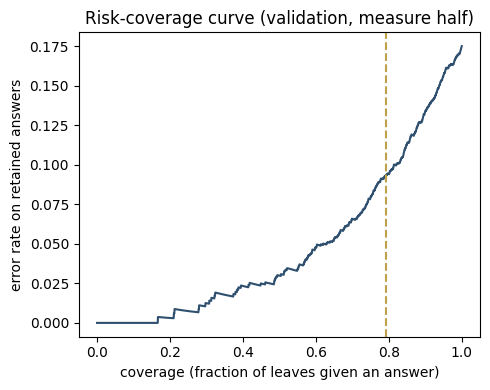

{
  "temperature": 0.9313,
  "threshold": 0.6455,
  "target_coverage": 0.8,
  "fitted_on": "validation split, stratified fit half (1,605 images), seed 42",
  "measured_on": "validation split, other half (1,605 images)",
  "model": "mobilenetv3_baseline.pt"
}


In [ ]:
import json
fit_confidence = torch.softmax(fit_logits / temperature, 1).max(1).values
target_coverage = 0.80
threshold = float(torch.quantile(fit_confidence, 1 - target_coverage))   # keep the most confident 80% of the fit half

measure_confidence, measure_prediction = after.max(1)
kept = measure_confidence >= threshold
realized_coverage = float(kept.float().mean())
selective_accuracy = float((measure_prediction[kept] == measure_targets[kept]).float().mean())
overall_accuracy = float((measure_prediction == measure_targets).float().mean())
print(f"threshold {threshold:.3f} | realized coverage {realized_coverage:.3f} | accuracy on retained {selective_accuracy:.4f} | accuracy on all {overall_accuracy:.4f} | accuracy on abstained {float((measure_prediction[~kept] == measure_targets[~kept]).float().mean()):.4f}")

# Risk-coverage curve: as the threshold rises, fewer answers are given and the retained ones are more accurate
order = torch.argsort(measure_confidence, descending=True)
correct_sorted = (measure_prediction[order] == measure_targets[order]).float()
coverage = np.arange(1, len(order) + 1) / len(order)
risk = 1 - correct_sorted.cumsum(0).numpy() / np.arange(1, len(order) + 1)
plt.figure(figsize=(5, 4)); plt.plot(coverage, risk, color="#2F4F6F"); plt.axvline(realized_coverage, color="#BFA14A", linestyle="--")
plt.xlabel("coverage (fraction of leaves given an answer)"); plt.ylabel("error rate on retained answers"); plt.title("Risk-coverage curve (validation, measure half)")
plt.tight_layout(); plt.savefig("/content/risk_coverage.png", dpi=150); plt.show()

json.dump({"temperature": round(temperature, 4), "threshold": round(threshold, 4), "target_coverage": target_coverage,
           "fitted_on": "validation split, stratified fit half (1,605 images), seed 42", "measured_on": "validation split, other half (1,605 images)",
           "model": "mobilenetv3_baseline.pt"}, open("/content/calibration.json", "w"), indent=2)
print(open("/content/calibration.json").read())